# 🎗️ Breast Cancer Classification
### Machine Learning | Random Forest

> Can we classify tumor samples as benign or malignant using measured cell features? We explore the dataset, train a Random Forest model, and compare its predictions with the known labels.


**Problem:** Binary Classification · **Target:** `diagnosis` (`B` = benign, `M` = malignant)  
**Source:** [Breast Cancer Wisconsin (Diagnostic) on Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)

*An educational classification exercise, not a cancer screening or diagnosis system.*

## Data Dictionary

> The dataset contains 569 samples and 33 columns, including 30 numeric features describing ten cell properties, a diagnosis column, an ID, and an empty column.

| Column | Meaning |
|---|---|
| `id` | Sample identifier (not a feature) |
| `diagnosis` | Target: `B` (benign), `M` (malignant) |
| `radius` | Mean distance from cell center to border |
| `texture` | Texture variation |
| `perimeter` | Cell perimeter |
| `area` | Cell area |
| `smoothness` | Surface smoothness variation |
| `compactness` | Compactness measurement |
| `concavity` | Concave contour characteristics |
| `concave points` | Number / extent of concave points |
| `symmetry` | Cell symmetry |
| `fractal_dimension` | Border complexity |
| `*_mean` | Average of the property |
| `*_se` | Standard error of the property |
| `*_worst` | Mean of the three largest observations |
| `Unnamed: 32` | Empty CSV column; removed before modeling |

## 1. Import Libraries and Load Data

> We open `data.csv` from the notebook folder and inspect the first rows

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. Exploratory Data Analysis

> We look at data types, missing values, and class balance

In [2]:
df.shape

(569, 33)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
df.isnull().sum()[df.isnull().sum() > 0]

Unnamed: 32    569
dtype: int64

In [5]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

## 3. Visualize the Data

> The charts compare diagnosis counts and cell radius across the two groups

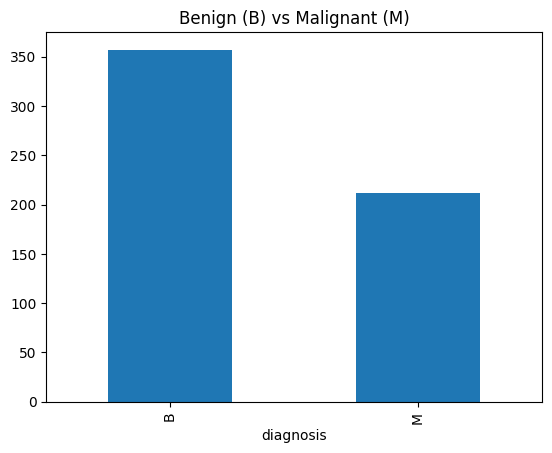

In [6]:
df['diagnosis'].value_counts().sort_index().plot(kind='bar')
plt.title('Benign (B) vs Malignant (M)')
plt.show()

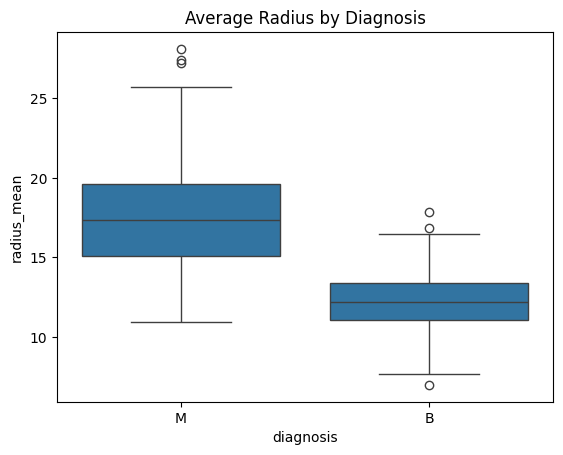

In [7]:
sns.boxplot(data=df, x='diagnosis', y='radius_mean')
plt.title('Average Radius by Diagnosis')
plt.show()

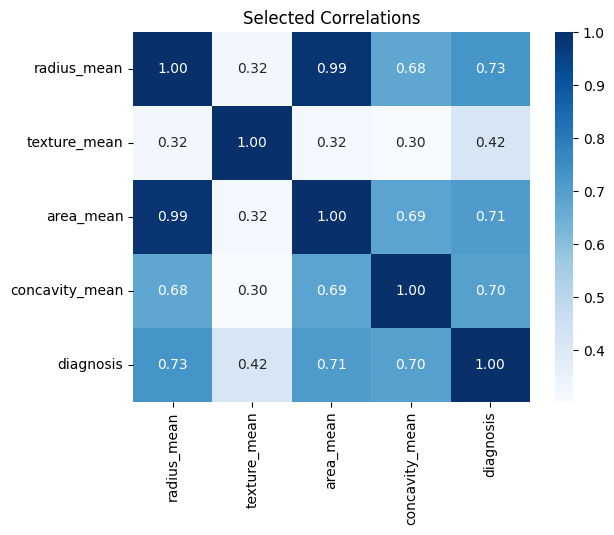

In [8]:
cols = ['radius_mean','texture_mean','area_mean','concavity_mean','diagnosis']
chart = df[cols].copy()
chart['diagnosis'] = chart['diagnosis'].map({'B':0,'M':1})
sns.heatmap(chart.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Selected Correlations')
plt.show()

## 4. Prepare X and y

> We remove the ID and empty column, then encode the diagnosis labels as 0 (benign) and 1 (malignant)

In [9]:
X = df.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])
y = df['diagnosis'].map({'B': 0, 'M': 1})
print('Features:', X.shape[1])

Features: 30


## 5. Split and Train

> We reserve 20% for testing. Random Forest combines many decision trees to produce a classification

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 6. Evaluate the Model

> We report overall accuracy and the precision, recall and F1-Score for malignant samples (`M = 1`)

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print('Accuracy:', round(accuracy_score(y_test, y_pred), 3))
print('Precision (M):', round(precision_score(y_test, y_pred), 3))
print('Recall (M):', round(recall_score(y_test, y_pred), 3))
print('F1-Score (M):', round(f1_score(y_test, y_pred), 3))

Accuracy: 0.974
Precision (M): 1.0
Recall (M): 0.929
F1-Score (M): 0.963


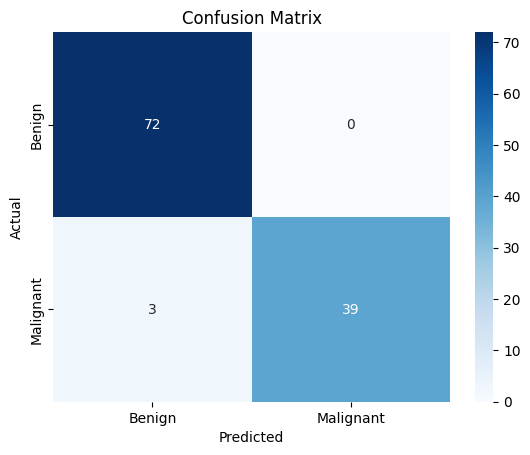

In [12]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 7. Feature Importance

> This chart shows the most important features according to the Random Forest model

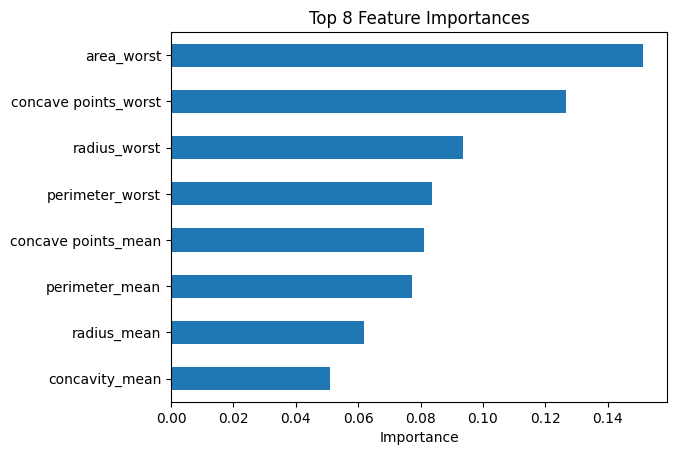

In [13]:
importance = pd.Series(model.feature_importances_, index=X.columns)
importance.nlargest(8).sort_values().plot(kind='barh', title='Top 8 Feature Importances')
plt.xlabel('Importance')
plt.show()

## 8. Conclusion

**Test results (80/20 split):** Accuracy **0.974**, Precision (malignant) **1.000**, Recall (malignant) **0.929**, F1 (malignant) **0.963**.


> The Random Forest learns patterns from the 30 measured features and predicts the two labels. Accuracy alone is not enough: recall for malignant samples and the confusion matrix are also important.

**Limitations:** A single small dataset and one random train/test split cannot establish clinical reliability. Feature importance is not proof of causality. This model must not be used for medical decisions.